# Custom ResNet-18 trên CIFAR-10

Thiết kế Residual Network bằng PyTorch, train từ đầu (không pretrained)
và tối ưu để đạt test accuracy >90%.

## 1. Bài toán

- Dataset: CIFAR-10
- Input: 3 × 32 × 32
- Classes: 10
- Framework: PyTorch
- Pretrained: None
- Target: Test accuracy >90%

Sử dụng Custom ResNet-18 với BasicBlock và residual connection.

> Chạy trên Kaggle: bật **Settings → Accelerator → GPU**, và bật **Internet** (hoặc Add Data một dataset CIFAR-10 có thư mục `cifar-10-batches-py`).

In [ ]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"  # mixed precision: ~2x nhanh hơn trên GPU Kaggle
torch.manual_seed(42)
torch.backends.cudnn.benchmark = True
print("Device:", device)

BATCH_SIZE = 128
EPOCHS = 40 
LR = 0.1
CHECKPOINT = "best_resnet18.pth"

Device: cuda


## 2. Dữ liệu

Chia phân tầng 45.000 train / 5.000 validation, test 10.000 ảnh.
Augmentation (RandomCrop + HorizontalFlip) chỉ áp dụng cho train.

In [2]:
# Kaggle thường tắt Internet: nếu đã Add Data CIFAR-10 thì copy sang ./data để torchvision dùng lại
kaggle_input = Path("/kaggle/input")
local = next(kaggle_input.rglob("cifar-10-batches-py"), None) if kaggle_input.exists() else None
if local and not Path("data/cifar-10-batches-py").exists():
    shutil.copytree(local, "data/cifar-10-batches-py")

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
train_transform = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean, std),
])
test_transform = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

train_data = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
val_data = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=test_transform)
test_data = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

train_idx, val_idx = train_test_split(
    np.arange(len(train_data)), test_size=0.1, random_state=42, stratify=train_data.targets)
train_dataset = Subset(train_data, train_idx)
val_dataset = Subset(val_data, val_idx)  # cùng ảnh gốc, nhưng không augmentation

loader_args = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=use_amp)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)
test_loader = DataLoader(test_data, shuffle=False, **loader_args)

print("Train / Val / Test:", len(train_dataset), len(val_dataset), len(test_data))

100%|██████████| 170M/170M [27:24<00:00, 104kB/s]  


Train / Val / Test: 45000 5000 10000


## 3. Custom ResNet-18

ResNet-18 gồm 8 BasicBlock, mỗi block có 2 convolution 3×3
và residual connection (identity hoặc projection shortcut).

CIFAR-10 dùng stem 3×3, stride 1 và không có MaxPool
để giữ thông tin không gian của ảnh 32×32.

```
Input (3, 32, 32)
→ Conv 3×3, 64
→ Layer1: 2 BasicBlock, 64 channels
→ Layer2: 2 BasicBlock, 128 channels
→ Layer3: 2 BasicBlock, 256 channels
→ Layer4: 2 BasicBlock, 512 channels
→ Global Average Pooling
→ FC 512 → 10
```

In [3]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = (nn.Identity() if stride == 1 and in_channels == out_channels else
                         nn.Sequential(nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                                       nn.BatchNorm2d(out_channels)))

    def forward(self, x):
        residual = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + residual)

class CIFARResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)
        self._init_weights()

    @staticmethod
    def _stage(in_channels, out_channels, stride):
        return nn.Sequential(BasicBlock(in_channels, out_channels, stride), BasicBlock(out_channels, out_channels))

    def _init_weights(self):
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(layer, nn.BatchNorm2d):
                nn.init.ones_(layer.weight)
                nn.init.zeros_(layer.bias)
        for layer in self.modules():
            if isinstance(layer, BasicBlock):
                nn.init.zeros_(layer.bn2.weight)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.fc(self.pool(x).flatten(1))

model = CIFARResNet18().to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 11173962


## 4. Training

- Loss: CrossEntropyLoss
- Optimizer: SGD, momentum 0.9, weight decay 5e-4
- Scheduler: CosineAnnealingLR
- Batch size: 128, LR: 0.1
- Lưu checkpoint tốt nhất theo validation accuracy

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def run_epoch(loader, train):
    model.train(train)
    loss_sum = correct = total = 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            loss_sum += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, 100 * correct / total


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc = 0
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    scheduler.step()
    for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
        history[key].append(value)
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), CHECKPOINT)
    print(f"Epoch {epoch:3d}/{EPOCHS} | train {train_loss:.4f}, {train_acc:.2f}% | val {val_loss:.4f}, {val_acc:.2f}%")
print("Best validation accuracy:", f"{best_acc:.2f}%")

Epoch   1/40 | train 1.7377, 35.51% | val 1.3976, 47.24%
Epoch   2/40 | train 1.2359, 54.77% | val 1.3058, 54.88%
Epoch   3/40 | train 0.9564, 65.56% | val 1.0337, 64.52%
Epoch   4/40 | train 0.7812, 72.47% | val 0.6867, 75.64%
Epoch   5/40 | train 0.6710, 76.67% | val 0.7112, 75.60%
Epoch   6/40 | train 0.6030, 79.04% | val 0.7978, 73.14%
Epoch   7/40 | train 0.5537, 81.03% | val 0.6008, 79.30%
Epoch   8/40 | train 0.5127, 82.43% | val 0.6448, 78.30%
Epoch   9/40 | train 0.4853, 83.28% | val 0.5520, 80.88%
Epoch  10/40 | train 0.4622, 84.01% | val 0.8364, 74.26%
Epoch  11/40 | train 0.4362, 85.06% | val 0.6279, 79.10%
Epoch  12/40 | train 0.4168, 85.74% | val 0.5814, 80.26%
Epoch  13/40 | train 0.3958, 86.49% | val 0.5447, 82.46%
Epoch  14/40 | train 0.3759, 87.21% | val 0.5271, 82.54%
Epoch  15/40 | train 0.3612, 87.70% | val 0.5916, 80.60%
Epoch  16/40 | train 0.3452, 88.24% | val 0.4606, 84.16%
Epoch  17/40 | train 0.3236, 88.96% | val 0.4088, 86.28%
Epoch  18/40 | train 0.3136, 89

## 5. Đánh giá

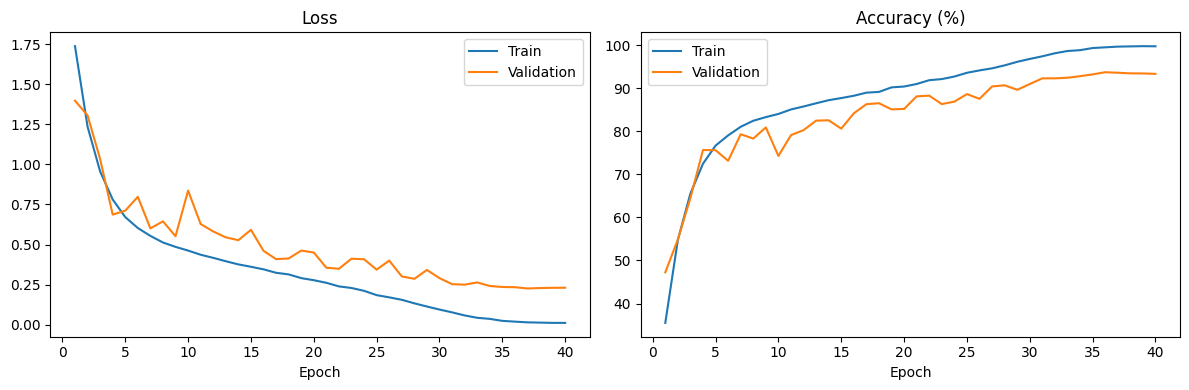

In [5]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Train")
plt.plot(epochs, history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="Train")
plt.plot(epochs, history["val_acc"], label="Validation")
plt.title("Accuracy (%)")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
test_loss, test_acc = run_epoch(test_loader, train=False)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%")
print("Target > 90%:", test_acc > 90)

Test Loss: 0.2478 | Test Accuracy: 93.40%
Target > 90%: True


## 6. Kết luận

- Kiến trúc: Custom ResNet-18 (BasicBlock + residual connection), không pretrained
- Dataset: CIFAR-10, framework: PyTorch
- Kết quả (best validation accuracy, test accuracy) in ở cell bên dưới; xem đường cong loss/accuracy ở trên để nhận xét hội tụ và overfitting.

In [7]:
print(f"Best validation accuracy: {best_acc:.2f}% | Test accuracy: {test_acc:.2f}% | Đạt >90%: {test_acc > 90}")

Best validation accuracy: 93.70% | Test accuracy: 93.40% | Đạt >90%: True
